# 📊 Notebook 01 — Análise Exploratória Inicial de Dados (EDA)

### Dataset: Cardiovascular Disease Prediction
### Disciplina: DCT1401 — Inteligência Artificial (UFRN)
### Aluna: Mariana dos Santos Batista Medeiros — Matrícula: 20230083988

Este notebook realiza a **exploração inicial do conjunto de dados**, com o objetivo de compreender sua estrutura e identificar problemas que deverão ser tratados antes das análises estatísticas e da modelagem.

Nesta etapa serão realizadas:

1. Carregamento e inspeção inicial dos dados
2. Identificação de valores ausentes
3. Detecção de outliers

As estatísticas descritivas, análises de distribuição e correlação serão realizadas após o tratamento dos dados, na etapa de pré-processamento.

> ⚠️ **Antes de começar:** certifique-se de que o arquivo `cardiovascular_disease_prediction.csv` está na pasta `data/raw/` do projeto.


## 🔧 Configuração Inicial

Nesta etapa são importadas as bibliotecas utilizadas ao longo do notebook e definidos os caminhos do projeto.

In [13]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Organização dos caminhos do projeto
from pathlib import Path

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 50)


# ---------------------------------------------------------
# Localização automática da raiz do projeto
# ---------------------------------------------------------

diretorio_atual = Path.cwd()

# Se o notebook estiver sendo executado dentro da pasta notebooks/
if diretorio_atual.name == "notebooks":
    raiz_projeto = diretorio_atual.parent

# Se estiver sendo executado a partir da raiz do projeto
elif (diretorio_atual / "data" / "raw").exists():
    raiz_projeto = diretorio_atual

else:
    raise FileNotFoundError(
        "Não foi possível localizar a estrutura do projeto."
    )


# ---------------------------------------------------------
# Caminhos utilizados no projeto
# ---------------------------------------------------------

caminho_dataset = (
    raiz_projeto
    / "data"
    / "raw"
    / "cardiovascular_disease_prediction.csv"
)

pasta_figuras = raiz_projeto / "reports" / "figures"

# Cria a pasta reports/figures caso ela ainda não exista
pasta_figuras.mkdir(parents=True, exist_ok=True)


print("Bibliotecas carregadas com sucesso!")
print(f"Raiz do projeto: {raiz_projeto}")

Bibliotecas carregadas com sucesso!
Raiz do projeto: c:\Users\farma\OneDrive\Documentos\IA\projeto_cardiovascular


---
# 📁 1. Carregamento e Inspeção Inicial

Nesta seção, carregamos o arquivo CSV e realizamos a primeira inspeção do conjunto de dados, verificando suas dimensões, colunas, tipos de dados e a natureza das variáveis.

> 💡 **O que estamos fazendo aqui?** Antes de qualquer tratamento, precisamos compreender a estrutura dos dados: quantas linhas e colunas existem, quais informações estão disponíveis e como cada variável foi armazenada.

In [2]:
# Carregamento do dataset
df = pd.read_csv(
    caminho_dataset,
    sep=",",
    encoding="utf-8"
)

print("O dataset foi carregado com sucesso!")
print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")

O dataset foi carregado com sucesso!
Dimensões: 20000 linhas x 35 colunas


### 1.1 Primeira inspeção visual

Vamos ver as **primeiras** e **últimas** linhas do dataset para ter uma ideia geral da estrutura dos dados.

In [3]:
# Primeiras 5 linhas
df.head()

,Patient_ID,Age,Gender,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Cholesterol,HDL,LDL,Triglycerides,Blood_Glucose,Diabetes,Hypertension,Smoking,Alcohol_Consumption,Physical_Activity,Exercise_Days_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Stress_Level,Family_History,Chest_Pain,Shortness_of_Breath,ECG_Result,Medication,Diet_Quality,Annual_Income_USD,Region,Education_Level,BMI_Category,Risk_Score,Cardiovascular_Disease
0,110651,41,Female,165.6,89.0,32.5,118,79,85,248,44.0,NaN,255.0,93.0,No,No,Yes,No,Moderate,7,56,8.5,High,No,No,No,Normal,No,Average,109870,Central,Bachelor,Obese,7.63,0
1,102042,43,Female,163.1,40.0,15.0,114,55,73,219,58.0,96.0,176.0,75.0,No,No,No,No,Moderate,2,42,7.0,Low,No,No,Yes,Normal,No,Poor,33025,North,Master,Underweight,2.96,0
2,108669,37,Female,154.0,96.2,40.6,127,74,68,219,23.0,107.0,231.0,118.0,No,No,Yes,Yes,Low,5,82,7.7,Moderate,No,No,No,Normal,No,Poor,53705,South,Bachelor,Obese,9.73,0
3,101115,81,Female,168.7,72.8,25.6,137,87,70,154,49.0,102.0,207.0,NaN,Yes,No,Yes,No,Moderate,4,111,8.0,Moderate,Yes,Yes,Yes,Normal,Yes,Average,172645,West,Bachelor,Overweight,15.81,1
4,113903,32,Female,176.7,53.1,17.0,144,79,66,225,58.0,96.0,136.0,121.0,No,Yes,Yes,No,Moderate,5,56,6.5,Moderate,Yes,No,No,Normal,Yes,Average,93228,West,High School,Underweight,9.40,0


In [4]:
# Últimas 5 linhas
df.tail()

,Patient_ID,Age,Gender,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Cholesterol,HDL,LDL,Triglycerides,Blood_Glucose,Diabetes,Hypertension,Smoking,Alcohol_Consumption,Physical_Activity,Exercise_Days_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Stress_Level,Family_History,Chest_Pain,Shortness_of_Breath,ECG_Result,Medication,Diet_Quality,Annual_Income_USD,Region,Education_Level,BMI_Category,Risk_Score,Cardiovascular_Disease
19995,111285,23,Female,182.4,76.9,23.1,168,96,82,122,44.0,131.0,106.0,95.0,No,Yes,Yes,No,Moderate,1,6,5.9,High,No,No,No,Normal,Yes,Average,87865,Central,High School,Normal,13.33,1
19996,111965,45,Female,158.0,69.0,27.6,133,78,96,290,52.0,150.0,117.0,143.0,Yes,No,Yes,No,NaN,0,0,7.7,Moderate,No,No,No,Abnormal,No,Average,70320,North,Bachelor,Overweight,12.79,1
19997,105391,60,Female,154.5,71.3,29.9,100,85,67,252,54.0,137.0,50.0,75.0,No,No,No,No,High,6,56,7.9,Moderate,No,Yes,No,Normal,Yes,Healthy,41961,Central,High School,Overweight,4.77,0
19998,100861,59,Male,182.4,76.0,22.8,99,79,73,212,93.0,84.0,231.0,100.0,No,No,Yes,No,Moderate,3,83,7.3,Moderate,Yes,No,No,Abnormal,No,Average,95349,North,Bachelor,Normal,5.87,0
19999,115796,34,Male,167.7,79.4,28.2,125,87,68,205,55.0,97.0,111.0,134.0,Yes,No,Yes,Yes,Low,1,65,8.2,High,Yes,No,No,Abnormal,Yes,NaN,160600,West,High School,Overweight,17.24,1


### 1.2 Dimensões, colunas e tipos de dados

Aqui vamos entender:
- Quantas linhas e colunas existem
- O nome de cada coluna
- O tipo de dado que cada coluna armazena (numérico, texto, etc.)

> 💡 **Por que isso importa?** Tipos errados podem causar problemas na análise. Por exemplo, uma variável que deveria ser numérica pode ter sido lida como texto se houver valores inválidos misturados.

In [5]:
print("Formato (linhas, colunas):", df.shape)
print("\nNomes das colunas:")
print(df.columns.tolist())

Formato (linhas, colunas): (20000, 35)

Nomes das colunas:
['Patient_ID', 'Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Heart_Rate', 'Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Blood_Glucose', 'Diabetes', 'Hypertension', 'Smoking', 'Alcohol_Consumption', 'Physical_Activity', 'Exercise_Days_Per_Week', 'Daily_Walking_Minutes', 'Sleep_Hours', 'Stress_Level', 'Family_History', 'Chest_Pain', 'Shortness_of_Breath', 'ECG_Result', 'Medication', 'Diet_Quality', 'Annual_Income_USD', 'Region', 'Education_Level', 'BMI_Category', 'Risk_Score', 'Cardiovascular_Disease']


In [6]:
# Informações detalhadas sobre cada coluna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient_ID                20000 non-null  int64  
 1   Age                       20000 non-null  int64  
 2   Gender                    20000 non-null  str    
 3   Height_cm                 20000 non-null  float64
 4   Weight_kg                 20000 non-null  float64
 5   BMI                       19400 non-null  float64
 6   Blood_Pressure_Systolic   20000 non-null  int64  
 7   Blood_Pressure_Diastolic  20000 non-null  int64  
 8   Heart_Rate                20000 non-null  int64  
 9   Cholesterol               20000 non-null  int64  
 10  HDL                       19400 non-null  float64
 11  LDL                       19400 non-null  float64
 12  Triglycerides             19400 non-null  float64
 13  Blood_Glucose             19400 non-null  float64
 14  Diabetes         

In [7]:
# Contagem de tipos de dados
df.dtypes.value_counts()

str        16
int64      10
float64     9
Name: count, dtype: int64

### 🏷️ Classificação das Variáveis

Embora o tipo armazenado no dataset (`dtype`) seja importante, a classificação abaixo considera também o significado de cada variável.

| Numéricas Contínuas | Numéricas Discretas | Categóricas Binárias | Categóricas Ordinais | Categóricas Nominais | Identificador |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `Height_cm` | `Age` | `Gender` | `Physical_Activity` | `Region` | `Patient_ID` |
| `Weight_kg` | `Exercise_Days_Per_Week` | `Diabetes` | `Stress_Level` | | |
| `BMI` | `Daily_Walking_Minutes` | `Hypertension` | `Diet_Quality` | | |
| `Blood_Pressure_Systolic` | | `Smoking` | `Education_Level` | | |
| `Blood_Pressure_Diastolic` | | `Alcohol_Consumption` | `BMI_Category` | | |
| `Heart_Rate` | | `Family_History` | | | |
| `Cholesterol` | | `Chest_Pain` | | | |
| `HDL` | | `Shortness_of_Breath` | | | |
| `LDL` | | `ECG_Result` | | | |
| `Triglycerides` | | `Medication` | | | |
| `Blood_Glucose` | | `Cardiovascular_Disease` | | | |
| `Sleep_Hours` | | | | | |
| `Risk_Score` | | | | | |
| `Annual_Income_USD` | | | | | |


---
## 🔍 2. Identificação de Valores Ausentes

Antes de realizar análises estatísticas e de correlação, é necessário identificar os valores ausentes presentes no conjunto de dados.

Nesta etapa, verificamos:
1. quais colunas apresentam dados faltantes;
2. a quantidade e o percentual de ausência;
3. o possível impacto desses valores nas etapas seguintes.

> 💡 Os valores ausentes serão apenas identificados neste notebook. A estratégia de tratamento será definida e aplicada no Notebook 02.

In [8]:
# Calculando valores ausentes por coluna
ausentes = df.isnull().sum()
ausentes_pct = (ausentes / len(df) * 100).round(2)

tabela_ausentes = pd.DataFrame({
    "qtd_ausentes": ausentes,
    "pct_ausentes": ausentes_pct
})
tabela_ausentes = tabela_ausentes[tabela_ausentes["qtd_ausentes"] > 0].sort_values(
    "qtd_ausentes", ascending=False
)

print(f"Total de colunas com valores ausentes: {len(tabela_ausentes)}")
print(f"Total geral de valores ausentes: {df.isnull().sum().sum()}\n")
tabela_ausentes

Total de colunas com valores ausentes: 8
Total geral de valores ausentes: 4800



,qtd_ausentes,pct_ausentes
BMI,600,3.0
HDL,600,3.0
LDL,600,3.0
Triglycerides,600,3.0
Blood_Glucose,600,3.0
Physical_Activity,600,3.0
Sleep_Hours,600,3.0
Diet_Quality,600,3.0


> 💡 **Observação importante:** As oito variáveis que apresentam valores ausentes possuem exatamente 600 registros faltantes, correspondendo a 3% da base em cada variável. Esse padrão uniforme pode estar relacionado à forma de geração ou coleta dos dados. Embora o percentual de ausência seja relativamente baixo, as variáveis afetadas possuem diferentes níveis de importância para a análise, sendo necessário considerar sua natureza e distribuição na etapa de pré-processamento. O tratamento dos valores ausentes será realizado no Notebook 02.


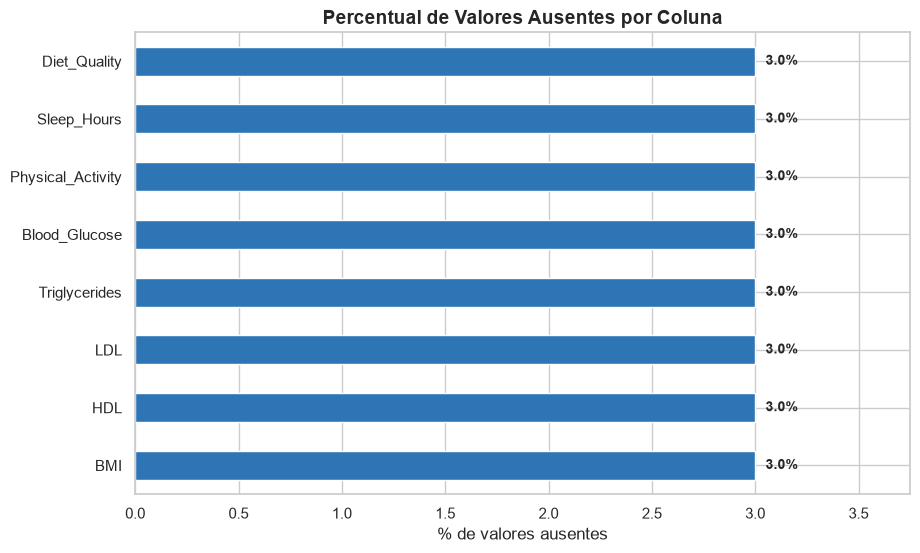

Gráfico salvo em: reports/figures/missing_values.png


In [9]:
# Visualização dos valores ausentes
fig, ax = plt.subplots(figsize=(10, 6))

tabela_ausentes_ordenada = tabela_ausentes["pct_ausentes"].sort_values()

tabela_ausentes_ordenada.plot(
    kind="barh",
    color="#2E75B6",
    ax=ax
)

ax.set_xlabel("% de valores ausentes")
ax.set_title("Percentual de Valores Ausentes por Coluna", fontsize=14, fontweight="bold")
ax.set_xlim(0, max(tabela_ausentes_ordenada) * 1.25)  # Dá espaço à direita para os textos

# Adicionar rótulos nas barras
for i, (val, name) in enumerate(zip(tabela_ausentes_ordenada, tabela_ausentes_ordenada.index)):
    ax.text(val + 0.05, i, f"{val:.1f}%", va="center", fontsize=10, fontweight="bold")

plt.savefig(
    pasta_figuras / "missing_values.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
print("Gráfico salvo em: reports/figures/missing_values.png")

### 📋 Impacto dos Valores Ausentes

Foram identificados valores ausentes em oito variáveis, todas com 3% de ausência. Embora o percentual seja relativamente baixo, esses dados devem ser tratados antes das análises estatísticas, de correlação e da modelagem.

**BMI (Numérica):** Como `Height_cm` e `Weight_kg` não apresentam valores ausentes, o BMI pode ser recalculado a partir dessas duas variáveis. No dataset, os valores existentes de BMI correspondem ao cálculo `peso / altura²`, considerando o arredondamento utilizado.

**HDL, LDL, Triglycerides e Blood_Glucose (Numéricas):** A presença de valores ausentes reduz a quantidade de informações disponíveis para as análises dessas variáveis. Será necessário definir uma estratégia de imputação adequada no pré-processamento.

**Sleep_Hours (Numérica):** Os valores ausentes também deverão ser tratados antes das análises estatísticas e da modelagem, considerando a distribuição da variável.

**Physical_Activity e Diet_Quality (Categóricas ordinais):** A ausência de categorias interfere nas frequências observadas e deverá ser tratada antes da codificação dessas variáveis.

As estratégias específicas de tratamento serão definidas e aplicadas no Notebook 02.


---
## 📦 3. Detecção de Outliers

Outliers são observações que se afastam do padrão geral de uma variável. Esses valores podem representar registros extremos legítimos ou possíveis inconsistências, portanto sua identificação não implica automaticamente que devam ser removidos.

Nesta etapa será utilizado o **método IQR (Intervalo Interquartil)**:

- Q1 = primeiro quartil (25%)
- Q3 = terceiro quartil (75%)
- IQR = Q3 - Q1
- Limite inferior = Q1 - 1,5 × IQR
- Limite superior = Q3 + 1,5 × IQR

Valores abaixo do limite inferior ou acima do limite superior serão sinalizados como possíveis outliers.

> 💡 A decisão de manter, transformar ou remover esses valores será tomada somente no Notebook 02.

In [10]:
# Selecionar variáveis numéricas adequadas para análise de outliers
# Patient_ID é apenas um identificador.
# Cardiovascular_Disease é categórica binária, apesar de estar armazenada como 0 e 1.
variaveis_outliers = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in ["Patient_ID", "Cardiovascular_Disease"]
]

print(f"Total de variáveis numéricas analisadas: {len(variaveis_outliers)}")
print(variaveis_outliers)

Total de variáveis numéricas analisadas: 17
['Age', 'Height_cm', 'Weight_kg', 'BMI', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Heart_Rate', 'Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Blood_Glucose', 'Exercise_Days_Per_Week', 'Daily_Walking_Minutes', 'Sleep_Hours', 'Annual_Income_USD', 'Risk_Score']


In [11]:
# Detecção de outliers pelo método IQR
resultados_outliers = []

for col in variaveis_outliers:
    serie = df[col].dropna()

    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = serie[
        (serie < limite_inferior) |
        (serie > limite_superior)
    ]

    resultados_outliers.append({
        "Variável": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Limite Inferior": limite_inferior,
        "Limite Superior": limite_superior,
        "Qtd Outliers": len(outliers),
        "% Outliers": (len(outliers) / len(serie)) * 100
    })

tabela_outliers = pd.DataFrame(resultados_outliers)

tabela_outliers.round(2)

,Variável,Q1,Q3,IQR,Limite Inferior,Limite Superior,Qtd Outliers,% Outliers
0,Age,36.00,69.00,33.00,-13.50,118.50,0,0.00
1,Height_cm,161.20,174.80,13.60,140.80,195.20,55,0.27
2,Weight_kg,61.90,82.30,20.40,31.30,112.90,60,0.30
3,BMI,21.50,29.80,8.30,9.05,42.25,164,0.85
4,Blood_Pressure_Systolic,113.00,137.00,24.00,77.00,173.00,64,0.32
5,Blood_Pressure_Diastolic,71.00,88.00,17.00,45.50,113.50,45,0.22
6,Heart_Rate,68.00,81.00,13.00,48.50,100.50,210,1.05
7,Cholesterol,177.00,232.00,55.00,94.50,314.50,44,0.22
8,HDL,44.00,64.00,20.00,14.00,94.00,71,0.37
9,LDL,96.00,143.00,47.00,25.50,213.50,61,0.31


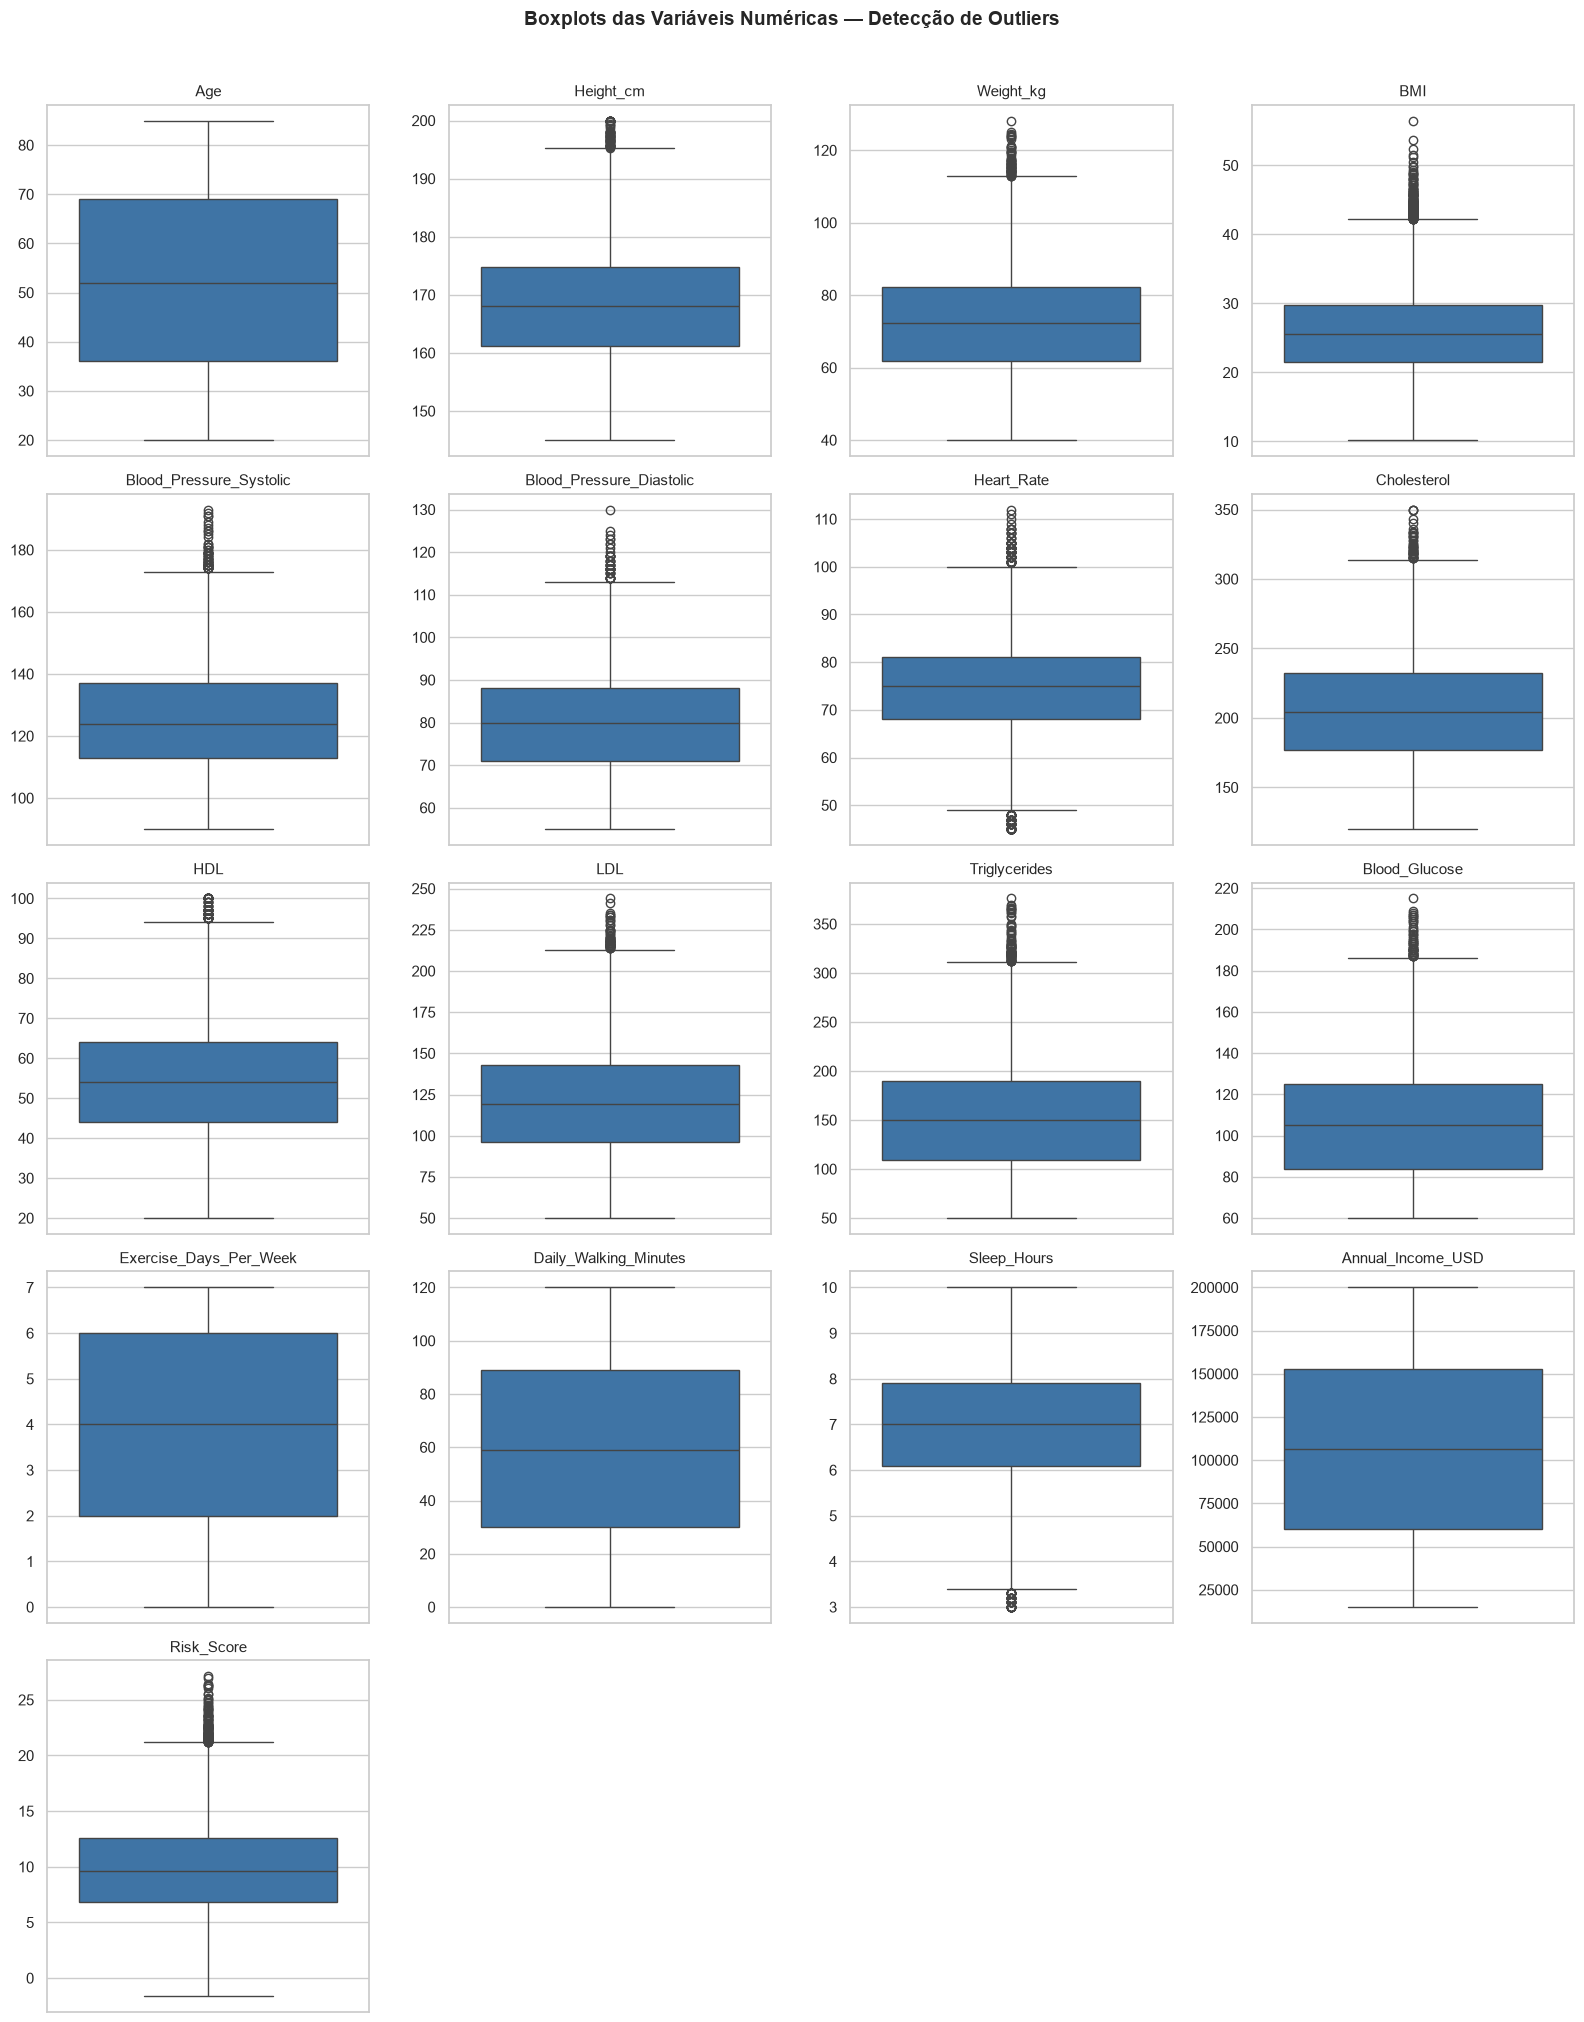

Gráfico salvo em: reports/figures/outliers_boxplot.png


In [12]:
# Boxplots das variáveis numéricas analisadas
n_colunas = 4
n_linhas = int(np.ceil(len(variaveis_outliers) / n_colunas))

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(16, 4 * n_linhas)
)

axes = axes.flatten()

for ax, col in zip(axes, variaveis_outliers):
    sns.boxplot(y=df[col], ax=ax, color="#2E75B6")
    ax.set_title(col, fontsize=11)
    ax.set_ylabel("")

# Remover espaços de gráficos não utilizados
for ax in axes[len(variaveis_outliers):]:
    ax.remove()

plt.suptitle(
    "Boxplots das Variáveis Numéricas — Detecção de Outliers",
    fontsize=14,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "outliers_boxplot.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo em: reports/figures/outliers_boxplot.png")

> 💡 **Interpretação dos outliers:**
>
> O método IQR identificou possíveis outliers em 13 das 17 variáveis numéricas analisadas. As maiores proporções ocorreram em `Heart_Rate` (aproximadamente 1,05%), `BMI` (0,85%) e `Risk_Score` (0,59%). Em `Age`, `Exercise_Days_Per_Week`, `Daily_Walking_Minutes` e `Annual_Income_USD`, o critério do IQR não identificou outliers.
>
> É importante destacar que um valor classificado como outlier pelo IQR não é necessariamente um erro. O método apenas identifica observações estatisticamente afastadas da região central dos dados.
>
> Esses valores extremos podem decorrer da variabilidade natural dos dados, de observações pouco frequentes ou de possíveis inconsistências de registro. Como não há evidência suficiente nesta etapa para determinar sua origem, cada caso deverá ser avaliado antes da definição do tratamento.
>
> Por esse motivo, nenhum valor será removido nesta etapa. A decisão de manter, transformar ou tratar os outliers será realizada no Notebook 02, considerando as características de cada variável e o possível impacto nas etapas posteriores.

---
## ✅ 4. Conclusão da Análise Exploratória Inicial

A análise exploratória inicial permitiu compreender a estrutura do conjunto de dados, composto por **20.000 registros e 35 variáveis**, incluindo variáveis numéricas, categóricas e um identificador.

Foram identificadas **oito variáveis com valores ausentes**, cada uma com 600 registros faltantes, correspondendo a **3% da base por variável**. Também foram detectados possíveis outliers em diversas variáveis numéricas por meio do método IQR e de boxplots.

Nesta etapa, os problemas foram apenas identificados. Nenhum valor ausente foi imputado e nenhum outlier foi removido ou transformado.

O tratamento dos valores ausentes e a decisão sobre os outliers serão realizados no **Notebook 02 — Limpeza e Pré-processamento**. Somente após esse tratamento serão realizadas as estatísticas descritivas, as análises de distribuição e a correlação entre as variáveis.
